In [1]:
# %pip install torch torchvision pytorchvideo opencv-python pandas numpy matplotlib scikit-learn

In [2]:
from pathlib import Path
import os
import sys
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    'cuda' if torch.cuda.is_available() else
    'mps' if torch.backends.mps.is_available() else 'cpu'
)

# check the root for the path
ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'starter' / 'cpr_data.py').is_file()
     and (p / 'train.csv').is_file()),
    None
)
if ROOT is None:
    raise FileNotFoundError

sys.path.insert(0, str(ROOT / 'starter'))
os.environ['CPR_DATA'] = str(ROOT)
import cpr_data
cpr_data.LOCAL_ROOT = str(ROOT)

OUTPUT_DIR = ROOT / 'outputs' / 'x3d_m'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Project:', ROOT)
print('Device:', DEVICE)
print('Torch:', torch.__version__)

Project: /Users/nikizheng/Desktop/CS541-CPR
Device: mps
Torch: 2.15.0


In [3]:
train = pd.read_csv(cpr_data.data_file('train.csv'))
sample = pd.read_csv(cpr_data.data_file('sample_submission.csv'))
labels = list(sample.columns[1:])
NUM_CLASSES = len(labels)
assert NUM_CLASSES == 13
assert set(labels).issubset(train.columns)

print('Training videos:', len(train))
print('Test videos:', len(sample))
print('Error labels:', labels)
display(train[['video_id', 'class_name', *labels]].head(3))

Training videos: 1008
Test videos: 4320
Error labels: ['e01_overlap_hands', 'e02_clenching_hands', 'e03_single_hand', 'e04_bending_arms', 'e05_tilting_arms', 'e06_jump_pressing', 'e07_squatting', 'e08_standing', 'e09_wrong_position', 'e10_insufficient_pressing', 'e11_slow_frequency', 'e12_excessive_pressing', 'e13_random_position_pressing']


,video_id,class_name,e01_overlap_hands,e02_clenching_hands,e03_single_hand,e04_bending_arms,e05_tilting_arms,e06_jump_pressing,e07_squatting,e08_standing,e09_wrong_position,e10_insufficient_pressing,e11_slow_frequency,e12_excessive_pressing,e13_random_position_pressing
0,CPR_Dataset_S0__C00_S0__r00__ch0,Correct,0,0,0,0,0,0,0,0,0,0,0,0,0
1,CPR_Dataset_S0__C00_S0__r00__ch1,Correct,0,0,0,0,0,0,0,0,0,0,0,0,0
2,CPR_Dataset_S0__C00_S0__r00__ch2,Correct,0,0,0,0,0,0,0,0,0,0,0,0,0


Train & Validation Split of 'take' recordings. MAke sure validation measures performance on different CPR attempts, not just different views of attempts the model has already seen.

In [4]:
take_table = train.groupby('take', as_index=False).agg(class_id=('class_id', 'first'))
class_take_counts = take_table['class_id'].value_counts()
print('Independent takes per class:')
display(class_take_counts.sort_index().rename('takes').to_frame())


train_takes, val_takes = train_test_split(
    take_table['take'], test_size=0.20, random_state=SEED,
    stratify=take_table['class_id']
)
train_split = train[train['take'].isin(train_takes)].reset_index(drop=True)
val_split = train[train['take'].isin(val_takes)].reset_index(drop=True)
print('Training videos:', len(train_split), 
      '\nValidation videos:', len(val_split))
display(pd.DataFrame({
    'train': train_split['class_name'].value_counts(),
    'validation': val_split['class_name'].value_counts()
}).fillna(0).astype(int))
print('View distribution:')
display(pd.DataFrame({
    'train': train_split['view'].value_counts(),
    'validation': val_split['view'].value_counts()
}).fillna(0).astype(int))

Independent takes per class:


,takes
class_id,
0,24
1,24
2,24
3,24
4,24
5,24
6,24
7,24
8,24


Training videos: 804 
Validation videos: 204


,train,validation
class_name,,
Bending Arms,57,15
Clenching Hands,57,15
Correct,57,15
Excessive Pressing,57,15
Insufficient Pressing,57,15
Jump Pressing,57,15
Overlap Hands,57,15
Random Position Pressing,57,15
Single Hand,57,15


View distribution:


,train,validation
view,,
ch0,268,68
ch1,268,68
ch2,268,68


### Read an video as a PyTorch tensor

Video: CPR_Dataset_S0__C00_S0__r00__ch0  class: Correct
[T,H,W,C]: (16, 256, 256, 3) torch.uint8
Sampled frame times (seconds): [0.  0.2 0.4 0.6 0.8 1.  1.2 1.4 1.6 1.8 2.  2.2 2.4 2.6 2.8 3. ]


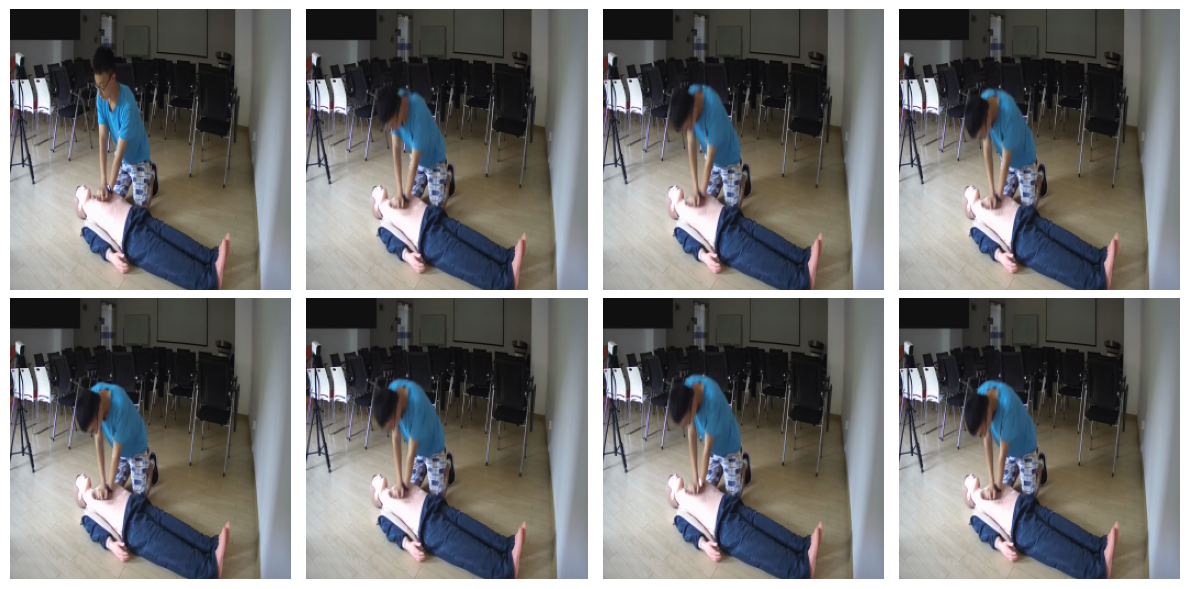

In [5]:
NUM_FRAMES = 16
FRAME_STRIDE = 5
SIZE = 256
FPS = 25  # frames per second

row = train.iloc[0]
video_path = cpr_data.video_file(row.video_id, 'train')
frames = cpr_data.load_video(
    video_path, stride=FRAME_STRIDE, max_frames=NUM_FRAMES, size=(SIZE, SIZE)
)
raw_video = torch.from_numpy(np.ascontiguousarray(frames))

print('Video:', row.video_id, ' class:', row.class_name)
print('[T,H,W,C]:', tuple(raw_video.shape), raw_video.dtype)
print('Sampled frame times (seconds):', (np.arange(len(frames)) * FRAME_STRIDE / FPS).round(2))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat:
    ax.axis('off')
for ax, idx in zip(axes.flat, np.linspace(0, len(frames)-1, min(8, len(frames)), dtype=int)):
    ax.imshow(frames[idx])
plt.tight_layout()
plt.show()

### Convert input to match X3D-m
X3D-M's expected input [B,C,T,H,W], so need to reorder our [T,H,W,C] to be [C,T,H,W], and also apply normalization with the X3D recipe's RGB mean 0.45 and standard deviation 0.225

In [10]:
def preprocess_video(frames, num_frames=NUM_FRAMES):
    if len(frames) == 0:
        raise ValueError('No frames')
    frames = frames[:num_frames]
    if len(frames) < num_frames:
        frames = np.concatenate(
            [frames, np.repeat(frames[-1:], num_frames - len(frames), axis=0)],
            axis=0
        )

    video = torch.from_numpy(np.ascontiguousarray(frames)).float() / 255.0
    video = video.permute(3, 0, 1, 2)      # [C,T,H,W]
    video = (video - 0.45) / 0.225        # X3D mean/std
    return video

x = preprocess_video(frames).unsqueeze(0).to(DEVICE)
print('Input shade:', tuple(x.shape))

Input shade: (1, 3, 16, 256, 256)


### Load pretrained X3D-M
Replace its original network ends in 400 classification to 13 for our case 

In [11]:
model = torch.hub.load(
    'facebookresearch/pytorchvideo', 'x3d_m', pretrained=True
)

head = model.blocks[-1]

d = head.proj.in_features
head.proj = nn.Linear(d, NUM_CLASSES)       # REPLACE to be our own class size
head.activation = nn.Identity()            # keep raw logits

model = model.to(DEVICE)
print('New classifier:', model.blocks[-1].proj)

Using cache found in /Users/nikizheng/.cache/torch/hub/facebookresearch_pytorchvideo_main


New classifier: Linear(in_features=2048, out_features=13, bias=True)


Forward pass after replacement

In [12]:
model.eval()
with torch.no_grad():
    logits = model(x)                       # forward only

print("Output shape:", logits.shape)

Output shape: torch.Size([1, 13])


### Freeze N-1 layers, finetune only the newly added fc layer.
freeze the pretrained backbone and train just the replacement layer, then measure held-out macro-F1.

In [ ]:
class CPRDataset(Dataset):
    def __init__(self, table):
        self.table = table.reset_index(drop=True)

    def __len__(self):
        return len(self.table)

    def __getitem__(self, idx):
        row = self.table.iloc[idx]
        frames = cpr_data.load_video(
            cpr_data.video_file(row.video_id, 'train'),
            stride=FRAME_STRIDE,
            max_frames=NUM_FRAMES,
            size=(SIZE, SIZE),
        )
        video = preprocess_video(frames)  
        target = torch.tensor(row[labels].to_numpy(dtype=np.float32))
        return video, target              # [3,T,H,W], [13]

BATCH_SIZE = 2  
train_loader = DataLoader(
    CPRDataset(train_split), batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0, pin_memory=(DEVICE.type == 'cuda'),
)
val_loader = DataLoader(
    CPRDataset(val_split), batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=(DEVICE.type == 'cuda'),
)

batch_video, batch_targets = next(iter(train_loader))
print('Video batch:', tuple(batch_video.shape))
print('Target batch:', tuple(batch_targets.shape))
assert batch_targets.shape[1] == NUM_CLASSES

Video batch: (2, 3, 16, 256, 256)
Target batch: (2, 13)


Freeze all pretrained weights, train only new FC

In [ ]:
# freeze all level first anad then unfreeze only the new fc layer
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.blocks[-1].proj.parameters():
    parameter.requires_grad = True

trainable = [
    (name, tuple(p.shape)) 
    for name, p in model.named_parameters() 
    if p.requires_grad]
print('Trainable tensors:', trainable)

criterion = nn.BCEWithLogitsLoss() # loss function with binary cross entropy
optimizer = torch.optim.AdamW(model.blocks[-1].proj.parameters(), lr=1e-3, weight_decay=1e-4)
EPOCHS = 5
THRESHOLD = 0.5
CHECKPOINT = OUTPUT_DIR / 'x3d_m_fc_only_best.pt'


Trainable tensors: [('blocks.5.proj.weight', (13, 2048)), ('blocks.5.proj.bias', (13,))]


### Evaluate with macro-F1

Apply sigmoid to obtain 13 scores in [0,1], then threshold each score to produce binary predictions.

In [ ]:
@torch.no_grad()
def evaluate(model, loader, threshold=THRESHOLD):
    model.eval()
    probs, truths = [], []
    total_loss = 0.0
    for videos, targets in loader:
        videos = videos.to(DEVICE)
        targets = targets.to(DEVICE)
        logits = model(videos)
        loss = criterion(logits, targets)
        total_loss += loss.item() * len(videos)
        probs.append(torch.sigmoid(logits).cpu().numpy()) # convert lofits into probabilities
        truths.append(targets.cpu().numpy().astype(int))

    y_prob = np.concatenate(probs, axis=0)  # [num_val_videos, 13]
    y_true = np.concatenate(truths, axis=0) # [num_val_videos, 13]
    y_pred = (y_prob >= threshold).astype(int)
    return {
        'loss': total_loss / len(loader.dataset),
        'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'precision_macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'y_true': y_true, 'y_prob': y_prob, 'y_pred': y_pred,
    }

def per_error_report(metrics):
    return pd.DataFrame({
        'error': labels,
        'validation_positives': metrics['y_true'].sum(axis=0),
        'predicted_positives': metrics['y_pred'].sum(axis=0),
        'precision': precision_score(metrics['y_true'], metrics['y_pred'], average=None, zero_division=0),
        'recall': recall_score(metrics['y_true'], metrics['y_pred'], average=None, zero_division=0),
        'f1': f1_score(metrics['y_true'], metrics['y_pred'], average=None, zero_division=0),
    })

pretrain_metrics = evaluate(model, val_loader)
print(f"Before training : "
      f"\nvalidation macro-F1={pretrain_metrics['macro_f1']:.4f} "
      f"\nvalidation BCE={pretrain_metrics['loss']:.4f}")


Before training : 
validation macro-F1=0.1149 
validation BCE=0.6950


Train the FC layer for a few epochs

In [ ]:
history = []
best_f1 = -1.0

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    model.eval()  # keep the freezen part untrain
    running_loss = 0.0

    for videos, targets in train_loader:
        videos = videos.to(DEVICE)
        targets = targets.to(DEVICE)

        optimizer.zero_grad(set_to_none=True) # clear previous gradient
        logits = model(videos)            # forward pass [Batch_sie,13]
        loss = criterion(logits, targets) # multi-label BCE loss
        loss.backward()                   # packpropagation
        optimizer.step()                  # update weight
        running_loss += loss.item() * len(videos)

    train_loss = running_loss / len(train_loader.dataset)
    valid = evaluate(model, val_loader) # evaluate each epoch
    history.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'val_loss': valid['loss'],
        'val_macro_f1': valid['macro_f1'],
        'val_macro_precision': valid['precision_macro'],
        'val_macro_recall': valid['recall_macro'],
    })

    # save the best epoch
    if valid['macro_f1'] > best_f1:
        best_f1 = valid['macro_f1']
        torch.save({
            'model_state_dict': model.state_dict(),
            'labels': labels,
            'epoch': epoch,
            'threshold': THRESHOLD,
            'val_macro_f1': best_f1,
            'strategy': 'fc_only',
        }, CHECKPOINT)

    print(f"Epoch {epoch}/{EPOCHS}: "
          f"train BCE={train_loss:.4f} | val BCE={valid['loss']:.4f} | "
          f"val macro-F1={valid['macro_f1']:.4f} | "
          f"time={time.time()-start:.1f}s")

history_df = pd.DataFrame(history)
display(history_df)

Epoch 1/5: train BCE=0.2084 | val BCE=0.1601 | val macro-F1=0.3582 | time=926.2s
Epoch 2/5: train BCE=0.1231 | val BCE=0.1155 | val macro-F1=0.4895 | time=927.7s
Epoch 3/5: train BCE=0.0922 | val BCE=0.0946 | val macro-F1=0.6424 | time=943.7s


Reload the best epoch, calculate validation metrics again, and got the F1 scores

In [ ]:
checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
best_metrics = evaluate(model, val_loader, threshold=checkpoint['threshold'])
print('Best epoch:', checkpoint['epoch'])
print(f"Validation macro-F1: {best_metrics['macro_f1']:.4f}")
print(f"Validation macro-precision: {best_metrics['precision_macro']:.4f}")
print(f"Validation macro-recall: {best_metrics['recall_macro']:.4f}")
display(per_error_report(best_metrics))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_df['epoch'], history_df['train_loss'], label='Training BCE')
axes[0].plot(history_df['epoch'], history_df['val_loss'], label='Validation BCE')
axes[0].set(xlabel='Epoch', ylabel='BCE loss', title='Training / validation loss')
axes[0].legend()
axes[1].plot(history_df['epoch'], history_df['val_macro_f1'], marker='o')
axes[1].set(xlabel='Epoch', ylabel='Macro-F1', title='Validation macro-F1', ylim=(0, 1))
plt.tight_layout()
plt.show()

Load the test dataset

In [ ]:
threshold = checkpoint['threshold']

model.eval()

all_predictions = []

with torch.no_grad():
    for video_id in sample['video_id']:

        # Load test video
        frames = cpr_data.load_video(
            cpr_data.video_file(video_id, 'test'),
            stride=FRAME_STRIDE,
            max_frames=NUM_FRAMES,
            size=(SIZE, SIZE)
        )

        # Preprocess: [T,H,W,C] -> [3,T,H,W]
        video = preprocess_video(frames)

        # Add batch dimension: [3,T,H,W] -> [1,3,T,H,W]
        video = video.unsqueeze(0).to(DEVICE)

        # Forward pass
        logits = model(video)

        # Convert logits to probabilities
        probabilities = torch.sigmoid(logits)

        # Convert probabilities to binary predictions
        predictions = (probabilities >= threshold).int()

        all_predictions.append(predictions[0].cpu().numpy())

all_predictions = np.array(all_predictions)

print('Test predictions:', all_predictions.shape)

### Export Submission


In [ ]:
submission = sample.copy()
submission[labels] = all_predictions
cpr_data.check_submission(submission, sample)

# Save CSV
submission_path = OUTPUT_DIR / 'submission.csv'
submission.to_csv(submission_path, index=False)

print('Submission saved:', submission_path)
display(submission.head())

In [ ]:
# Number of predicted errors per test video
error_counts = submission[labels].sum(axis=1)

print('Predicted errors per video:')
print(error_counts.value_counts().sort_index())

print('Total test videos:', len(submission))
print('Videos predicted correct:', (error_counts == 0).sum())
print('Videos with multiple predicted errors:', (error_counts >= 2).sum())